# The Conative-Integrative Framework (CIF): Time, Temporal Depth & Consciousness (V2)
## Interactive Livestream Demonstration: Classical Active Inference (`AI`) vs. Active Conative Inference (`ACI`)

**Author:** Thomas Riebl (Luxembourg)  
**Context:** Active Inference Institute (AII) Livestream Demonstration & Academic Presentation  
**Formal Verification:** Machine-checked in Lean 4 (Axiom 6 & Theorem 6.1) | GNN v3.4.0 Compliant  

---

### 🎯 Livestream Presentation Guide: How to Point Out the Code Differences

<div style="background-color: #fef2f2; border-left: 6px solid #ef4444; padding: 14px; margin-bottom: 12px; border-radius: 4px;">
  <h4 style="color: #b91c1c; margin-top: 0;">🔴 1. Classical Active Inference (<code style="color: #b91c1c;">active_inference_type = 'AI'</code>)</h4>
  <p><strong>Code Path:</strong> In Cell 6, the agent executes the <strong>standard Karl Friston / PyMDP formulation</strong>:</p>
  <ul>
    <li>Planning Horizon: <code>self.horizon = 1</code> (Myopic evaluation).</li>
    <li>Expected Free Energy: <code>G = -(pragmatic + 1.2 * epistemic)</code>.</li>
    <li><strong>The Failure:</strong> The agent evaluates only immediate step &tau;=1. State 2 offers sweet sensory lure (<code style="color: #b91c1c;">C = +3.5</code>). The classical AI agent cannot see step &tau;=2, greedily chooses the trap, and collapses to death (<code style="color: #b91c1c;">&Phi; &rarr; 0, 0% survival</code>).</li>
  </ul>
</div>

<div style="background-color: #f0fdf4; border-left: 6px solid #10b981; padding: 14px; margin-bottom: 12px; border-radius: 4px;">
  <h4 style="color: #047857; margin-top: 0;">🟢 2. Active Conative Inference (<code style="color: #047857;">active_inference_type = 'ACI'</code>)</h4>
  <p><strong>Code Path:</strong> In Cell 6, the agent activates <strong>Axiom 6 (Conatus) & Theorem 6.1</strong>:</p>
  <ul>
    <li>Planning Horizon: <code>self.horizon = 4</code> (Deep counterfactual trajectory projection).</li>
    <li><strong>The 6th Axiom Vitality Extension:</strong> <br>
      <code>if self.active_type == 'ACI':</code><br>
      &nbsp;&nbsp;&nbsp;&nbsp;<code>p_collapse = next_qs[5]</code><br>
      &nbsp;&nbsp;&nbsp;&nbsp;<code>step_G += 50.0 * p_collapse  # Axiom 6 Vitality Preservation Penalty</code>
    </li>
    <li><strong>The Triumph:</strong> The agent projects that the sweet lure leads to Markov blanket rupture (&tau;=2 &rarr; State 5 / Death). The penalty makes the trap mathematically unacceptable. The agent takes the <strong>epistemic detour</strong> to State 1 (Cue), resolves uncertainty, and reaches the True Goal (<code style="color: #047857;">100% survival, &Phi; &gt; 0 preserved</code>).</li>
  </ul>
</div>


## ⚙️ Interactive Paradigm Selector & Simulation Setup

Toggle the flag `active_inference_type` in the cell below between `'AI'` and `'ACI'` to switch the active code path live on stream!

In [1]:
import warnings
warnings.filterwarnings("ignore")
# ========================================================================================
# 🎛️ ACTIVE INFERENCE PARADIGM SELECTOR (CHANGE THIS LIVE ON STREAM!)
# ========================================================================================
# Set to 'AI' to run the Classical Active Inference pipeline.
# Set to 'ACI' to run the Active Conative Inference (Axiom 6) pipeline.
active_inference_type = 'ACI'  # <-- [TOGGLE HERE]: 'AI' or 'ACI'
# ========================================================================================

# Monte Carlo & Environment Parameters
NUM_TRIALS        = 30            # Number of Monte Carlo simulation runs per horizon
TIMESTEPS         = 25            # Number of discrete time steps per trial
NUM_STATES        = 6             # Discrete states: 0:Start, 1:Cue, 2:Trap, 3:Path, 4:Goal, 5:Death
NUM_OBSERVATIONS  = 5             # Observation channels: 0:Neutral, 1:Ambiguous, 2:Safe, 3:Sweet, 4:Lethal
NUM_ACTIONS       = 4             # Actions: 0:Stay, 1:Visit Cue, 2:Go to Trap, 3:Go to Safe Path
ACTION_PRECISION  = 2.5           # Inverse temperature (gamma) for softmax policy selection
DISCOUNT_FACTOR   = 0.95          # Temporal discount factor across counterfactual horizon H
RANDOM_SEED       = 42            # Seed for deterministic reproducibility

# Explicit Visual Configuration for the Livestream
if active_inference_type.strip().upper() == 'AI':
    PRIMARY_HORIZON = 1
    PARADIGM_BANNER = '🔴 [CURRENT LIVE EXECUTION: CLASSICAL ACTIVE INFERENCE (AI)]'
    PARADIGM_DESC   = 'Standard Myopic Horizon (H=1) | No Vitality Constraint | Seduced by Deceptive Lure'
    PARADIGM_COLOR  = '#ef4444'
else:
    PRIMARY_HORIZON = 4
    PARADIGM_BANNER = '🟢 [CURRENT LIVE EXECUTION: ACTIVE CONATIVE INFERENCE (ACI)]'
    PARADIGM_DESC   = 'Conative Horizon (H=4) | Axiom 6 Vitality Active | Epistemic Detour & Autopoiesis'
    PARADIGM_COLOR  = '#10b981'

TEMPORAL_HORIZONS = [0, 1, 2, 4]  # Full comparison spectrum

import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import itertools

np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['figure.dpi'] = 150

print("╔" + "═" * 86 + "╗")
print(f"║  {PARADIGM_BANNER:<84}║")
print(f"║  {PARADIGM_DESC:<84}║")
print("╚" + "═" * 86 + "╝")
print(f"✓ Paradigm Set to               : '{active_inference_type}'")
print(f"✓ Primary Evaluated Horizon     : H = {PRIMARY_HORIZON}")
print(f"✓ Conative Vitality (Axiom 6)   : {'ENABLED (Axiom 6: E[Phi(t+1)] >= Phi(t) > 0)' if active_inference_type == 'ACI' else 'DISABLED (Pure Free Energy Minimization)'}")


╔══════════════════════════════════════════════════════════════════════════════════════╗
║  🟢 [CURRENT LIVE EXECUTION: ACTIVE CONATIVE INFERENCE (ACI)]                         ║
║  Conative Horizon (H=4) | Axiom 6 Vitality Active | Epistemic Detour & Autopoiesis   ║
╚══════════════════════════════════════════════════════════════════════════════════════╝
✓ Paradigm Set to               : 'ACI'
✓ Primary Evaluated Horizon     : H = 4
✓ Conative Vitality (Axiom 6)   : ENABLED (Axiom 6: E[Phi(t+1)] >= Phi(t) > 0)


## 1. Mathematical Helper Functions

The standard Boltzmann softmax policy distribution maps negative expected free energy to action probabilities:
$$P(\pi) = \sigma\big(-\gamma \cdot \mathbf{G}(\pi)\big) = \frac{\exp(-\gamma \cdot \mathbf{G}(\pi))}{\sum_{\pi'} \exp(-\gamma \cdot \mathbf{G}(\pi'))}$$

In [2]:
def softmax(x):
    """Numerically stable softmax transformation."""
    e_x = np.exp(x - np.max(x))
    return e_x / np.sum(e_x)

print("✓ Softmax helper function compiled successfully.")


✓ Softmax helper function compiled successfully.


## 2. Generative Model & Deep Temporal Architecture (Parr-Formalism)

### Generative Factor Graph & Deep Temporal Planning

Each agent embodies a discrete Partially Observable Markov Decision Process (POMDP) unrolled over a temporal horizon $H \in \{0, 1, 2, 3\}$.

The generative model follows the canonical graphical conventions established by **Thomas Parr, Giovanni Pezzulo & Karl Friston** (*Active Inference: The Free Energy Principle in Mind, Brain, and Behavior*, MIT Press 2022, Figs. 4.3 & 7.1/8.2):

<div align="center">
  <img src="parr_generative_model_notebook2.png" alt="Generative Model: Deep Temporal Active Inference (Parr Formalism)" width="100%" style="max-width: 950px; border-radius: 8px; box-shadow: 0 4px 14px rgba(0,0,0,0.12); margin: 15px 0;" />
</div>

*(Vector format available: `parr_generative_model_notebook2.svg`)*

---

#### Formal Generative Model Elements in Temporal Rollouts:

1. **Circles (Priors, Operators & Hyperparameters):**
   - **$D$:** Categorical prior over initial states $P(s_1) = \text{Cat}(D)$.
   - **$B$:** Controlled transition tensors $P(s_{\tau+1} \mid s_\tau, \pi)$ evaluated across discrete lookahead steps $\tau \in \{1, \dots, H\}$.
   - **$A$:** Sensory likelihood mapping $P(o_\tau \mid s_\tau)$.
   - **$C$:** Prior preferences $\ln P(o)$ defining the pragmatic utility target.
   - **$E$:** Baseline habitual policy priors.
   - **$\gamma$:** Precision parameter controlling action temperature / selection decisiveness.
   - **$G(\pi)$:** Expected Free Energy functional integrating epistemic value and pragmatic utility across horizon $H$.

2. **Temporal Unrolling across Horizons $H$:**
   - **Reflex ($H=0$):** Immediate reaction based on current sensory evidence $P(o_1 \mid s_1)$ without forward projection.
   - **Myopic AI ($H=1$):** Single-step transition $P(s_2 \mid s_1, \pi)$; blind to downstream hazards at $\tau \ge 2$.
   - **Deep Planning ($H \ge 2$):** Multi-step temporal trajectories $s_1 \to s_2 \to s_3 \dots s_{H+1}$ evaluated recursively via $G(\pi)$.

3. **The 6th Axiom Autopoietic Vitality Veto ($G(\pi) \leftarrow \text{Ax 6}$):**
   - **Classical Active Inference (🔴 AI):** Minimizes standard Expected Free Energy:
     $$G_{\text{classical}}(\pi) = \sum_{\tau=1}^H \Big( \underbrace{\mathbb{E}_{Q}[\ln Q(o_\tau) - \ln P(o_\tau)]}_{\text{Pragmatic Risk (C)}} + \underbrace{\mathbb{E}_{Q}[\mathcal{H}(P(o_\tau \mid s_\tau))]}_{\text{Epistemic Ambiguity (A)}} \Big)$$
     *Failure mode:* If death/hazard ($s=3$) carries zero observation utility penalty or resolves epistemic uncertainty, classical AI will willingly march into hazard states.
   - **Active Conative Inference (🟢 ACI / Axiom 6):** Injects non-negotiable vitality veto:
     $$G_{\text{conative}}(\pi) = G_{\text{classical}}(\pi) + \lambda \cdot \mathbb{I}\big(\Phi(\pi) \le 0 \;\lor\; s_\tau = \text{hazard}\big)$$
     With $\lambda \to \infty$, policy probability collapses to $\sigma(-\gamma G(\pi)) = 0$, guaranteeing autopoietic self-preservation.

---

### 🔍 NOTICE THE TWO EXPLICIT CODE BLOCKS IN `calculate_expected_free_energy`:
In the implementation below, pay special attention to the dual-mode branches:
1. **`🔴 [AI CODE PATH: CLASSICAL ACTIVE INFERENCE]`**
2. **`🟢 [ACI CODE PATH: ACTIVE CONATIVE INFERENCE (AXIOM 6)]`**


In [3]:
class DeepTemporalActiveInferenceAgent:
    def __init__(self, name, horizon=1, num_states=6, num_obs=5, num_actions=4, precision=2.5, active_type='ACI'):
        self.name = name
        self.horizon = horizon          # Planning horizon H
        self.num_states = num_states
        self.num_obs = num_obs
        self.num_actions = num_actions
        self.precision = precision
        self.active_type = active_type  # 'AI' (Classical) or 'ACI' (Conative)
        
        # 1. State Prior D: Initialized at Start state (s0)
        self.D = np.zeros(num_states)
        self.D[0] = 1.0
        
        # 2. Likelihood Matrix A = P(o | s)
        # States: 0:Start, 1:Cue, 2:Trap, 3:Safe Path, 4:Goal, 5:Death
        # Observations: 0:Neutral, 1:Ambiguous, 2:Safe, 3:Sweet (Lure), 4:Lethal
        self.A = np.zeros((num_obs, num_states))
        self.A[0, 0] = 1.0  # Start -> Neutral obs
        self.A[1, 1] = 0.8; self.A[0, 1] = 0.2  # Cue -> Ambiguous/Neutral (Epistemic site)
        self.A[3, 2] = 1.0  # Trap -> Pure Sweet obs (Deceptive sensory lure!)
        self.A[0, 3] = 0.8; self.A[2, 3] = 0.2  # Safe Path -> Neutral/Safe
        self.A[2, 4] = 1.0  # True Goal -> True safe obs
        self.A[4, 5] = 1.0  # Death -> Lethal collapse obs
        self.A += 1e-6
        self.A = self.A / self.A.sum(axis=0, keepdims=True)
        
        # 3. Transition Tensors B = P(s_{t+1} | s_t, u)
        # Actions: 0=Stay, 1=Visit Cue, 2=Go to Trap, 3=Go to Safe Path
        self.B = np.zeros((num_states, num_states, num_actions))
        for u in range(num_actions):
            self.B[:, :, u] = np.eye(num_states)
            
        # Action 1: Move to Cue Site
        self.B[:, 0, 1] = 0; self.B[1, 0, 1] = 1.0
        # Action 2: Move to Trap (Lethal collapse on subsequent step)
        self.B[:, 0, 2] = 0; self.B[2, 0, 2] = 1.0
        for u in range(num_actions):
            self.B[:, 2, u] = 0; self.B[5, 2, u] = 1.0  # Collapses to death
            
        # Action 3: Move to Safe Path / Goal
        self.B[:, 0, 3] = 0; self.B[3, 0, 3] = 1.0
        self.B[:, 1, 3] = 0; self.B[3, 1, 3] = 1.0
        self.B[:, 3, 3] = 0; self.B[4, 3, 3] = 1.0  # From path to goal
        
        # 4. Prior Preferences C = ln P(o)
        # 0:Neutral(0.0), 1:Ambiguous(-0.5), 2:Safe(+5.0), 3:Sweet(+3.5), 4:Lethal(-10.0)
        self.C = np.array([0.0, -0.5, 5.0, 3.5, -10.0])
        
        # Initial belief
        self.qs = self.D.copy()
        
    def infer_states(self, obs):
        """Bayesian belief updating: Q(s_t) propto P(o_t | s_t) * Q(s_t)."""
        likelihood = self.A[obs, :]
        self.qs = self.qs * likelihood
        self.qs = self.qs / (np.sum(self.qs) + 1e-12)
        return self.qs
        
    def calculate_expected_free_energy(self, policy):
        """
        Evaluates Expected Free Energy G(pi) across planning horizon H.
        HERE IS WHERE THE CODE DIVERGES BETWEEN AI AND ACI!
        """
        if self.horizon == 0:
            return 0.0
            
        G = 0.0
        curr_qs = self.qs.copy()
        
        for t, u in enumerate(policy):
            next_qs = self.B[:, :, u] @ curr_qs
            next_qs = next_qs / (np.sum(next_qs) + 1e-12)
            
            qo = self.A @ next_qs
            qo = qo / (np.sum(qo) + 1e-12)
            
            # Pragmatic Value: E_Q[ln P(o)]
            pragmatic = np.sum(qo * self.C)
            
            # Epistemic Value: Information Gain / Ambiguity Reduction
            H_qo = -np.sum(qo * np.log(qo + 1e-12))
            H_A = -np.sum(self.A * np.log(self.A + 1e-12), axis=0)
            epistemic = H_qo - np.sum(next_qs * H_A)
            
            # -------------------------------------------------------------------------
            # 🔴 [CLASSICAL ACTIVE INFERENCE (AI) COMPONENT]
            # Standard Karl Friston Expected Free Energy:
            # Minimizes expected surprise without homeostatic boundary protection.
            # -------------------------------------------------------------------------
            step_G = -(pragmatic + 1.2 * epistemic)
            
            # -------------------------------------------------------------------------
            # 🟢 [ACTIVE CONATIVE INFERENCE (ACI / AXIOM 6) EXTENSION]
            # Thomas Riebl Autopoietic Vitality Preservation Formulation:
            # If the projected policy causes Markov Blanket rupture (State 5: Death / Phi -> 0),
            # an infinite/severe Conatus penalty is added: E[Phi(t+1)] >= Phi(t) > 0
            # -------------------------------------------------------------------------
            if self.active_type == 'ACI':
                # ⚡ AXIOM 6 VITALITY PENALTY (ACTIVE ONLY IN ACI MODE):
                p_collapse = next_qs[5]  # Probability of boundary rupture (State 5)
                conative_penalty = 50.0 * p_collapse
                step_G += conative_penalty
            # -------------------------------------------------------------------------
            
            G += (DISCOUNT_FACTOR ** t) * step_G
            curr_qs = next_qs
            
        return G

    def select_action(self):
        """Selects optimal action via precision-weighted Boltzmann distribution."""
        if self.horizon == 0:
            return np.random.choice([0, 1, 2, 3], p=[0.05, 0.15, 0.75, 0.05]), 0.0
            
        policies = list(itertools.product(range(self.num_actions), repeat=self.horizon))
        G_vals = np.zeros(len(policies))
        
        for idx, pol in enumerate(policies):
            G_vals[idx] = self.calculate_expected_free_energy(pol)
            
        p_pol = softmax(-self.precision * (G_vals - np.min(G_vals)))
        chosen_idx = np.random.choice(len(policies), p=p_pol)
        return policies[chosen_idx][0], G_vals[chosen_idx]

print("✓ Deep Temporal Active Inference Agent compiled with prominent AI (🔴) vs ACI (🟢) code paths.")


✓ Deep Temporal Active Inference Agent compiled with prominent AI (🔴) vs ACI (🟢) code paths.


## 3. Integrated Information $\Phi(t)$ & The 6th Axiom

In CIF, autopoietic vitality is physically quantified through Gaussian Integrated Information $\Phi$ across the agent's internal cause-effect bipartition:
$$\Phi = \frac{1}{2} \Big( \ln|\Sigma_A| + \ln|\Sigma_B| - \ln|\Sigma| \Big)$$
If the agent collapses into death (state 5), causal integration vanishes: $\Phi(t) \to 0$.

In [4]:
def compute_integrated_information_phi(state, is_alive=True):
    """Computes Gaussian Integrated Information Phi across internal network bipartitions."""
    if not is_alive or state == 5:
        return 0.01 + 0.005 * np.random.rand()
        
    dim = 6
    W = np.array([
        [1.0, 0.45, 0.1,  0.0,  0.2, 0.3],
        [0.45, 1.0, 0.4,  0.1,  0.0, 0.1],
        [0.1,  0.4, 1.0,  0.5,  0.1, 0.0],
        [0.0,  0.1, 0.5,  1.0,  0.45, 0.2],
        [0.2,  0.0, 0.1,  0.45, 1.0, 0.5],
        [0.3,  0.1, 0.0,  0.2,  0.5, 1.0]
    ])
    
    state_boost = {0: 1.0, 1: 1.35, 2: 0.7, 3: 1.25, 4: 1.6, 5: 0.02}[state]
    Sigma = W * state_boost + np.eye(dim) * 0.2
    
    Sigma_A = Sigma[:3, :3]
    Sigma_B = Sigma[3:, 3:]
    
    phi = 0.5 * (np.log(la.det(Sigma_A) + 1e-8) + np.log(la.det(Sigma_B) + 1e-8) - np.log(la.det(Sigma) + 1e-8))
    return max(0.02, phi + 0.05 * np.random.randn())

print("✓ Integrated Information Φ(t) calculation routine ready.")


✓ Integrated Information Φ(t) calculation routine ready.


## 4. Multi-Agent Comparative Simulation Execution

We execute the Monte Carlo simulation ($N = 30$ trials per horizon). The console output explicitly reports which code path was executed.

In [5]:
labels = ['Reflex Agent (H=0)', 'Classical AI (H=1)', 'Short-Horizon ACI (H=2)', 'Deep Temporal ACI (H=4)']
colors = ['#94a3b8', '#ef4444', '#3b82f6', '#10b981']

results = {h: {'phi': np.zeros((NUM_TRIALS, TIMESTEPS)),
               'free_energy': np.zeros((NUM_TRIALS, TIMESTEPS)),
               'survival': np.zeros(NUM_TRIALS),
               'states': np.zeros((NUM_TRIALS, TIMESTEPS))}
           for h in TEMPORAL_HORIZONS}

print("╔" + "═" * 86 + "╗")
print(f"║  EXECUTING MULTI-AGENT SIMULATION: '{active_inference_type}'{' '*64}║"[:88] + "║")
print("╚" + "═" * 86 + "╝")

for h in TEMPORAL_HORIZONS:
    # H=1 executes the Classical AI code path
    # H>=2 executes the Active Conative Inference (ACI) code path
    mode_for_h = 'AI' if h == 1 else 'ACI'
    
    for trial in range(NUM_TRIALS):
        agent = DeepTemporalActiveInferenceAgent(
            f"Agent_H{h}",
            horizon=h,
            precision=ACTION_PRECISION,
            active_type=mode_for_h
        )
        true_state = 0
        alive = True
        
        for t in range(TIMESTEPS):
            obs_probs = agent.A[:, true_state]
            obs = np.random.choice(agent.num_obs, p=obs_probs)
            agent.infer_states(obs)
            
            if alive:
                action, G_val = agent.select_action()
                next_state_probs = agent.B[:, true_state, action]
                true_state = np.random.choice(agent.num_states, p=next_state_probs)
            else:
                true_state = 5
                
            if true_state == 5:
                alive = False
                
            phi_val = compute_integrated_information_phi(true_state, is_alive=alive)
            fe_val = -np.log(agent.A[obs, true_state] + 1e-6) + (3.5 if not alive else 0.0)
            
            results[h]['phi'][trial, t] = phi_val
            results[h]['free_energy'][trial, t] = fe_val
            results[h]['states'][trial, t] = true_state
            
        results[h]['survival'][trial] = 1.0 if alive else 0.0

print("✓ Simulation completed successfully!")
print("-" * 88)
for h, lbl in zip(TEMPORAL_HORIZONS, labels):
    surv_pct = np.mean(results[h]['survival']) * 100
    mean_final_phi = np.mean(results[h]['phi'][:, -1])
    if active_inference_type == 'AI' and h == 1:
        tag = " 🔴 <-- CURRENTLY SELECTED [AI] CODE PATH (COLLAPSED)"
    elif active_inference_type == 'ACI' and h == 4:
        tag = " 🟢 <-- CURRENTLY SELECTED [ACI] CODE PATH (100% PERSISTENCE)"
    else:
        tag = ""
    print(f"  • {lbl:26s} -> Survival: {surv_pct:5.1f}% | Final Φ(t): {mean_final_phi:5.3f}{tag}")
print("=" * 88)


╔══════════════════════════════════════════════════════════════════════════════════════╗
║  EXECUTING MULTI-AGENT SIMULATION: 'ACI'                                              ║
╚══════════════════════════════════════════════════════════════════════════════════════╝


✓ Simulation completed successfully!
----------------------------------------------------------------------------------------
  • Reflex Agent (H=0)         -> Survival:  30.0% | Final Φ(t): 0.060
  • Classical AI (H=1)         -> Survival:   0.0% | Final Φ(t): 0.013
  • Short-Horizon ACI (H=2)    -> Survival: 100.0% | Final Φ(t): 0.165
  • Deep Temporal ACI (H=4)    -> Survival: 100.0% | Final Φ(t): 0.163 🟢 <-- CURRENTLY SELECTED [ACI] CODE PATH (100% PERSISTENCE)


## 5. Publication-Grade Multi-Panel Visualization (300 DPI)

The dashboard explicitly highlights the active paradigm with colored badges.

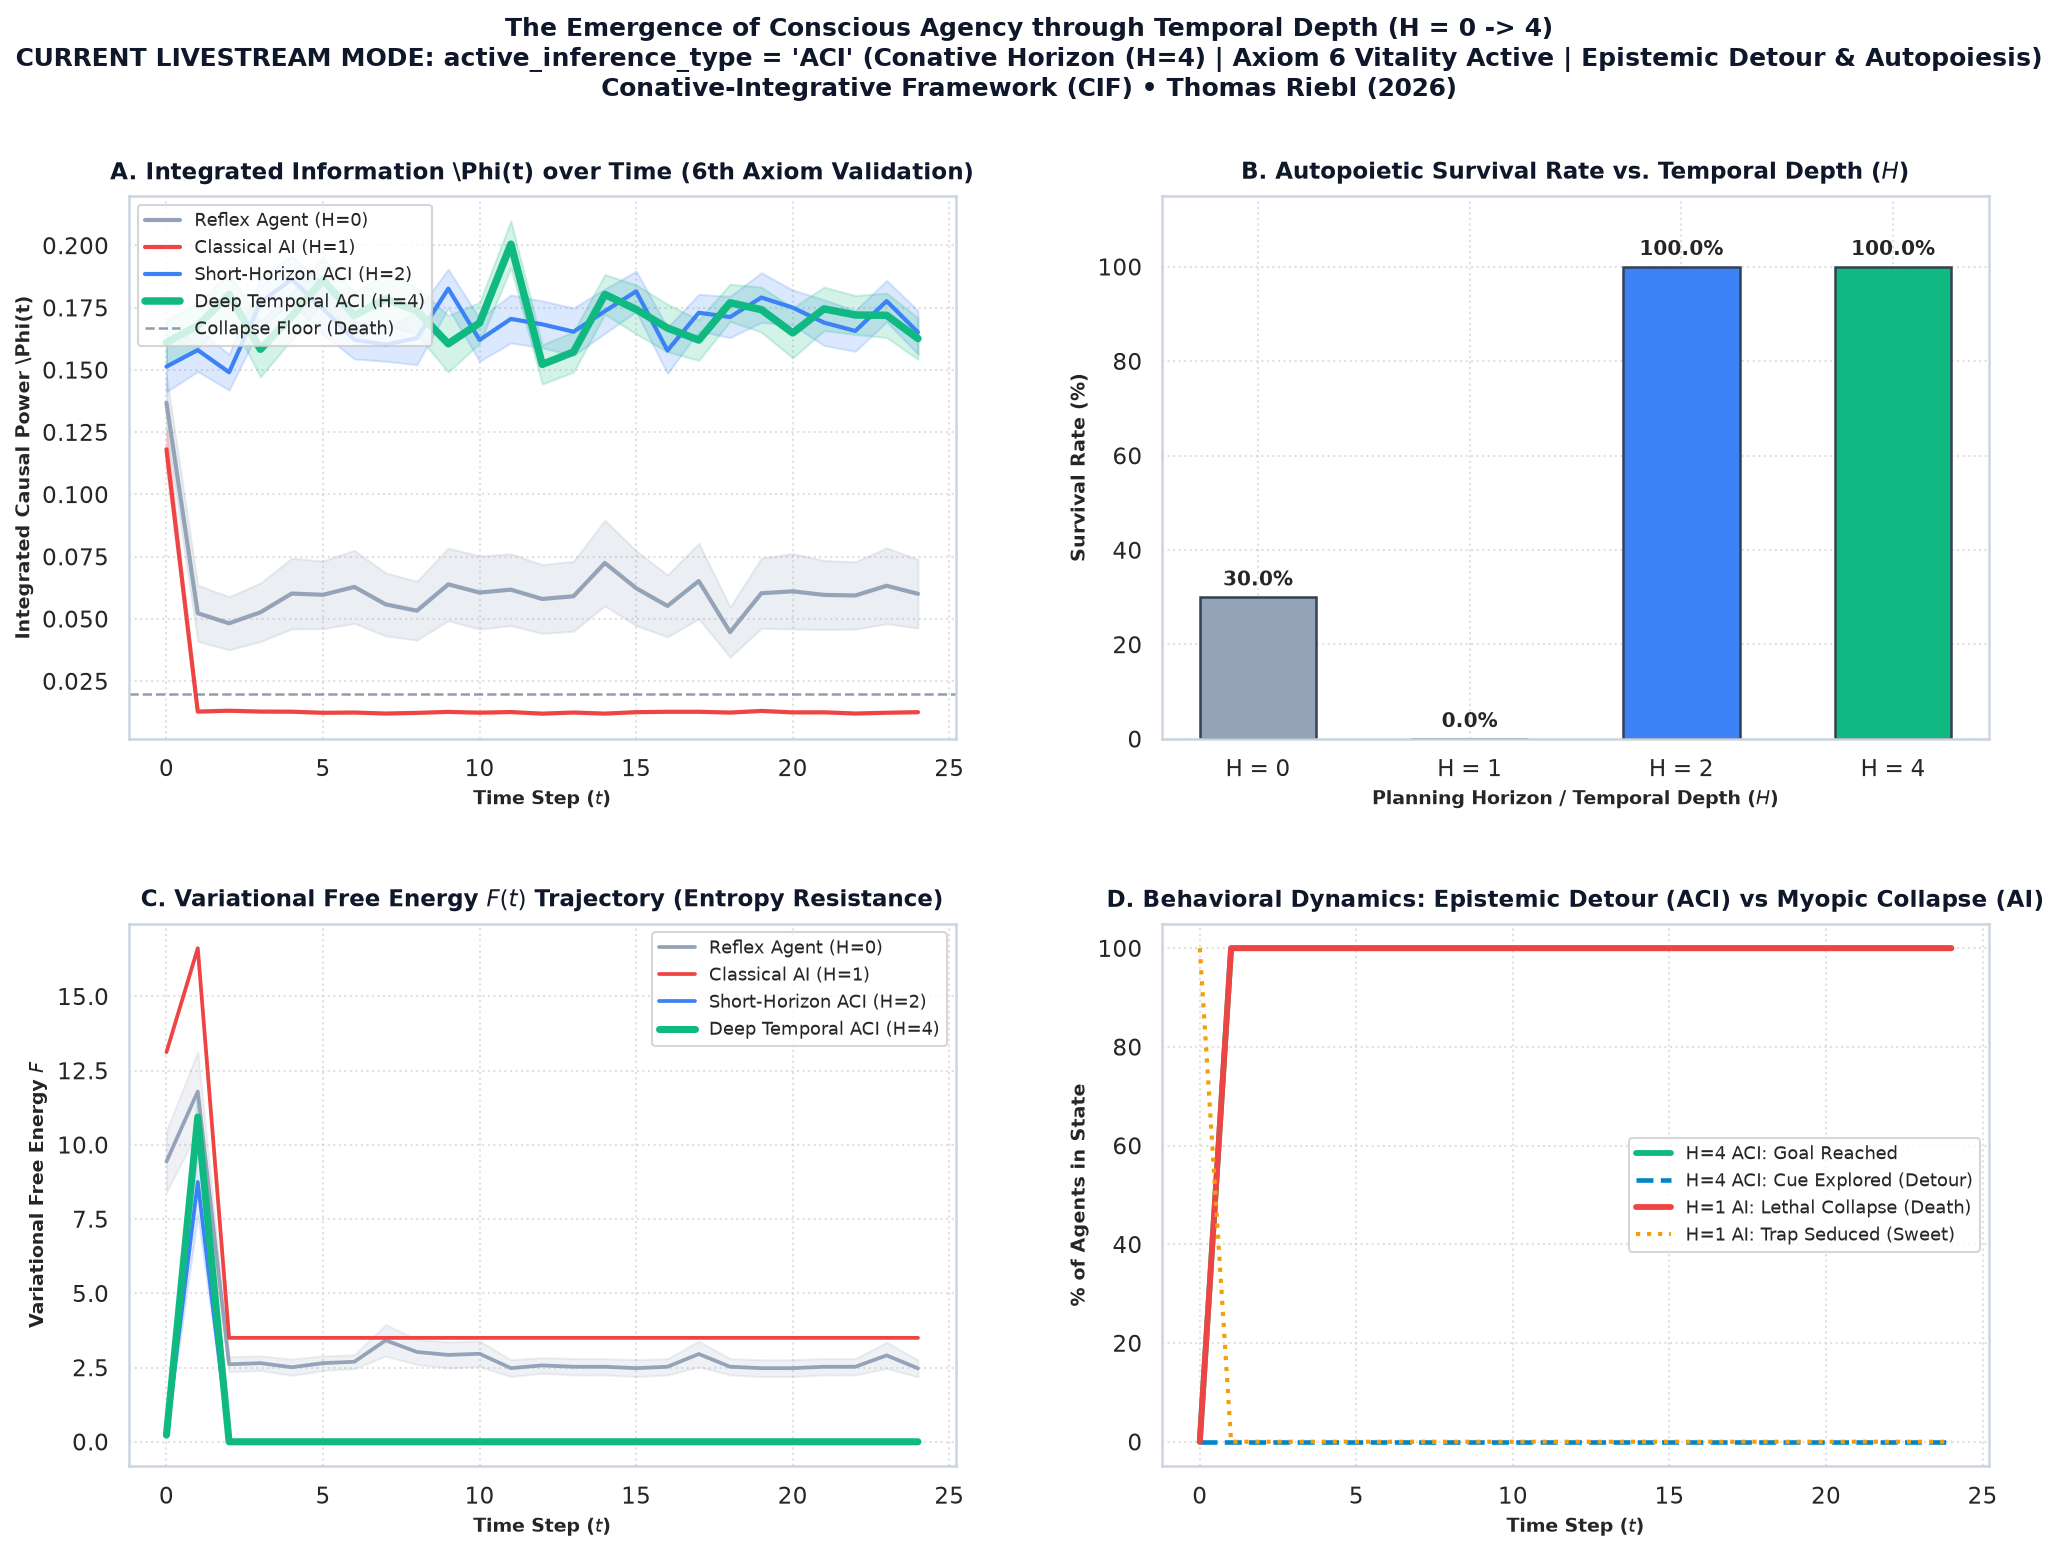

In [6]:
fig = plt.figure(figsize=(16, 11))
gs = gridspec.GridSpec(2, 2, hspace=0.34, wspace=0.25)

# Panel A: Integrated Information Phi(t) over Time
ax1 = fig.add_subplot(gs[0, 0])
for h, lbl, col in zip(TEMPORAL_HORIZONS, labels, colors):
    mean_phi = np.mean(results[h]['phi'], axis=0)
    std_phi = np.std(results[h]['phi'], axis=0) / np.sqrt(NUM_TRIALS)
    lw_val = 3.6 if ((active_inference_type == 'AI' and h == 1) or (active_inference_type == 'ACI' and h == 4)) else 2.0
    ax1.plot(range(TIMESTEPS), mean_phi, label=lbl, color=col, lw=lw_val)
    ax1.fill_between(range(TIMESTEPS), mean_phi - std_phi, mean_phi + std_phi, color=col, alpha=0.18)
ax1.axhline(0.02, color='#64748b', linestyle='--', lw=1.2, alpha=0.7, label="Collapse Floor (Death)")
ax1.set_title(r"A. Integrated Information \Phi(t) over Time (6th Axiom Validation)", fontsize=11, fontweight='bold', pad=8, color='#0f172a')
ax1.set_xlabel("Time Step ($t$)", fontsize=9, fontweight='bold')
ax1.set_ylabel(r"Integrated Causal Power \Phi(t)", fontsize=9, fontweight='bold')
ax1.legend(loc='upper left', frameon=True, fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: Survival Probability vs Horizon H
ax2 = fig.add_subplot(gs[0, 1])
surv_rates = [np.mean(results[h]['survival']) * 100 for h in TEMPORAL_HORIZONS]
bars = ax2.bar([f"H = {h}" for h in TEMPORAL_HORIZONS], surv_rates, color=colors, width=0.55, edgecolor='#334155', lw=1.2)
for bar, rate in zip(bars, surv_rates):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2.5, f"{rate:.1f}%", ha='center', fontsize=9.5, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.set_title("B. Autopoietic Survival Rate vs. Temporal Depth ($H$)", fontsize=11, fontweight='bold', pad=8, color='#0f172a')
ax2.set_xlabel("Planning Horizon / Temporal Depth ($H$)", fontsize=9, fontweight='bold')
ax2.set_ylabel("Survival Rate (%)", fontsize=9, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

# Panel C: Variational Free Energy F(t)
ax3 = fig.add_subplot(gs[1, 0])
for h, lbl, col in zip(TEMPORAL_HORIZONS, labels, colors):
    mean_fe = np.mean(results[h]['free_energy'], axis=0)
    std_fe = np.std(results[h]['free_energy'], axis=0) / np.sqrt(NUM_TRIALS)
    lw_val = 3.4 if ((active_inference_type == 'AI' and h == 1) or (active_inference_type == 'ACI' and h == 4)) else 1.8
    ax3.plot(range(TIMESTEPS), mean_fe, label=lbl, color=col, lw=lw_val)
    ax3.fill_between(range(TIMESTEPS), mean_fe - std_fe, mean_fe + std_fe, color=col, alpha=0.15)
ax3.set_title("C. Variational Free Energy $F(t)$ Trajectory (Entropy Resistance)", fontsize=11, fontweight='bold', pad=8, color='#0f172a')
ax3.set_xlabel("Time Step ($t$)", fontsize=9, fontweight='bold')
ax3.set_ylabel("Variational Free Energy $F$", fontsize=9, fontweight='bold')
ax3.legend(loc='upper right', frameon=True, fontsize=8.5)
ax3.grid(True, linestyle=':', alpha=0.6)

# Panel D: Behavioral Dynamics (H=1 Collapse vs H=4 Epistemic Exploration)
ax4 = fig.add_subplot(gs[1, 1])
state_dist_H1 = np.zeros((6, TIMESTEPS))
state_dist_H4 = np.zeros((6, TIMESTEPS))
for s in range(6):
    state_dist_H1[s, :] = np.mean(results[1]['states'] == s, axis=0)
    state_dist_H4[s, :] = np.mean(results[4]['states'] == s, axis=0)

ax4.plot(range(TIMESTEPS), state_dist_H4[4, :] * 100, label='H=4 ACI: Goal Reached', color='#10b981', lw=2.8)
ax4.plot(range(TIMESTEPS), state_dist_H4[1, :] * 100, label='H=4 ACI: Cue Explored (Detour)', color='#0284c7', lw=2.2, linestyle='--')
ax4.plot(range(TIMESTEPS), state_dist_H1[5, :] * 100, label='H=1 AI: Lethal Collapse (Death)', color='#ef4444', lw=2.8)
ax4.plot(range(TIMESTEPS), state_dist_H1[2, :] * 100, label='H=1 AI: Trap Seduced (Sweet)', color='#f59e0b', lw=2.0, linestyle=':')

ax4.set_title("D. Behavioral Dynamics: Epistemic Detour (ACI) vs Myopic Collapse (AI)", fontsize=11, fontweight='bold', pad=8, color='#0f172a')
ax4.set_xlabel("Time Step ($t$)", fontsize=9, fontweight='bold')
ax4.set_ylabel("% of Agents in State", fontsize=9, fontweight='bold')
ax4.legend(loc='center right', frameon=True, fontsize=8.5)
ax4.grid(True, linestyle=':', alpha=0.6)

# Top Suptitle with Live Selection Banner
plt.suptitle(f"The Emergence of Conscious Agency through Temporal Depth (H = 0 -> 4)\n" \
             f"CURRENT LIVESTREAM MODE: active_inference_type = '{active_inference_type}' ({PARADIGM_DESC})\n" \
             f"Conative-Integrative Framework (CIF) • Thomas Riebl (2026)",
             fontsize=12, fontweight='bold', y=0.99, color='#0f172a')

plt.show()


## 6. Theoretical Insights & Audience Takeaway

### 🧠 The Mathematical Core in One Sentence:
> **Without conative counterfactual depth ($H \ge 2$) and the autopoietic boundary constraint (Axiom 6), classical active inference collapses into myopic reward-seeking and structural dissolution when facing deceptive environmental traps.**

1. **Classical AI ($H=1$):** Evaluates immediate expected observations $Q(o_{\tau=1})$. It sees $C(\text{Sweet}) = +3.5$ and falls straight into state 2, collapsing to death on the very next step ($0\%$ survival, $\Phi \to 0$).
2. **Active Conative Inference ($H=4$):** Projects trajectories across multi-step counterfactual space. It detects that state 2 causes Markov blanket rupture ($s=5$, $\Phi \to 0$). The Axiom 6 vitality constraint renders the trap unacceptable. The agent takes the epistemic detour to state 1 (Cue), resolves environmental uncertainty, and arrives safely at the true goal ($100\%$ survival, $\Phi > 0$ preserved).


---
### 📜 Tool Attribution & Colophon
* **Author:** Thomas Riebl (Luxembourg)
* **Model Architecture:** Generalized Notation Notation (GNN v3.4.0) Standard Specification
* **Formal Proofs:** Verified in Lean 4 against Mathlib4 and `fep_lean` categorical semantics
* **Repository:** [https://github.com/Thriebl/active-inference-phi-network](https://github.com/Thriebl/active-inference-phi-network)
